# Customer Churn — Exploratory Data Analysis (EDA)

This notebook inspects the cleaned Telco Customer Churn dataset (`data/interim/telco_churn_cleaned.csv`) to understand:
- Churn class balance
- Numeric distributions (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Churn rates across `Contract`, `InternetService`, `PaymentMethod`, and `TechSupport`


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/interim/telco_churn_cleaned.csv')
print('Shape:', df.shape)
print('Missing values:\n', df.isnull().sum()[df.isnull().sum() > 0])
df.head()


Shape: (7021, 20)
Missing values:
 Series([], dtype: int64)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,'No phone service',DSL,No,Yes,No,No,No,No,Month-to-month,Yes,'Electronic check',29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,'One year',No,'Mailed check',56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,'Mailed check',53.85,108.15,1
3,Male,0,No,No,45,No,'No phone service',DSL,Yes,No,Yes,Yes,No,No,'One year',No,'Bank transfer (automatic)',42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,'Fiber optic',No,No,No,No,No,No,Month-to-month,Yes,'Electronic check',70.70,151.65,1


Churn Rate: 26.45%


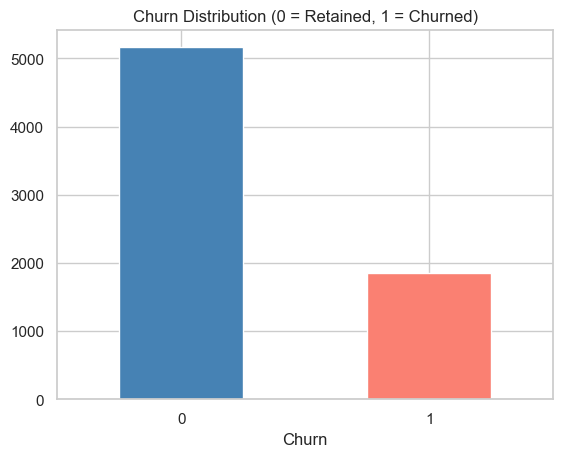

In [2]:
# 1. Target Distribution
print('Churn Rate:', f"{df['Churn'].mean():.2%}")
df['Churn'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Churn Distribution (0 = Retained, 1 = Churned)')
plt.xticks(rotation=0)
plt.show()


In [3]:
# 2. Churn Rate by Key Categories
for col in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']:
    print(f'\n--- Churn Rate by {col} ---')
    print((df.groupby(col)['Churn'].mean() * 100).round(2).sort_values(ascending=False))



--- Churn Rate by Contract ---
Contract
Month-to-month    42.64
'One year'        11.27
'Two year'         2.83
Name: Churn, dtype: float64

--- Churn Rate by InternetService ---
InternetService
'Fiber optic'    41.78
DSL              18.89
No                7.21
Name: Churn, dtype: float64

--- Churn Rate by PaymentMethod ---
PaymentMethod
'Electronic check'             45.15
'Mailed check'                 18.92
'Bank transfer (automatic)'    16.71
'Credit card (automatic)'      15.24
Name: Churn, dtype: float64

--- Churn Rate by TechSupport ---
TechSupport
No                       41.50
Yes                      15.17
'No internet service'     7.21
Name: Churn, dtype: float64


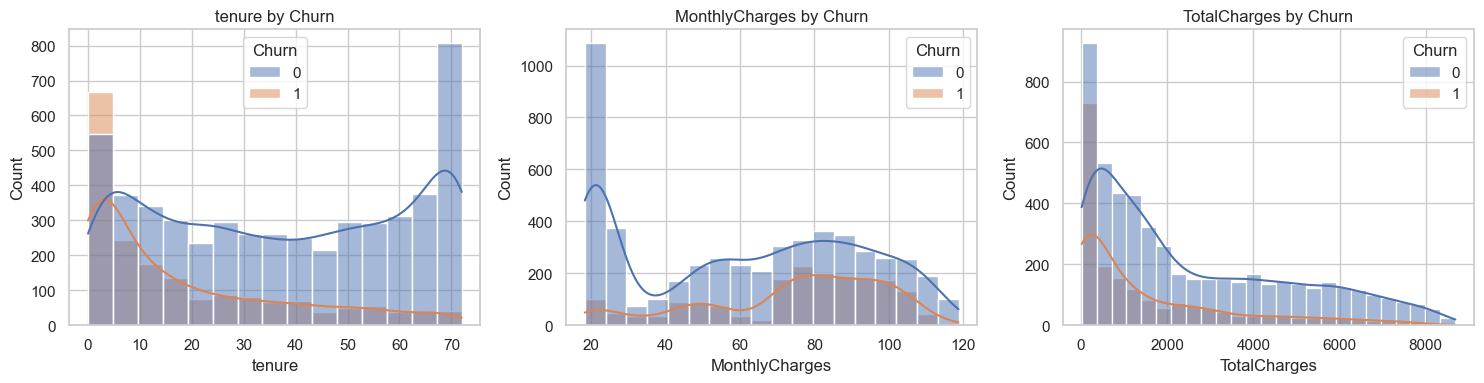

In [4]:
# 3. Numeric Distributions by Churn
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=ax)
    ax.set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()


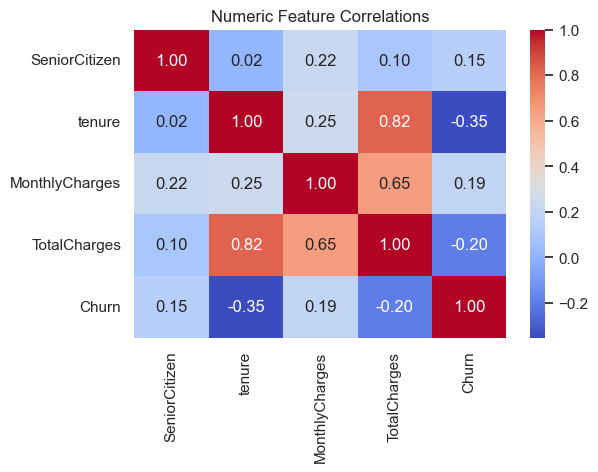

In [5]:
# 4. Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Numeric Feature Correlations')
plt.show()
